# Week 3 — Subset Selection, PCR and PLS

**The task** are there better ways to deal with near-copies?

- **Forward selection** — starts empty and adds the most useful column one at a time.
- **Backward elimination** — starts with all columns and removes the least useful one at a time.
- **PCR** — **merges** columns into a few summary "components", without looking at bankruptcy.
  Like summarising 78 ratios as a few overall scores.
- **PLS** — also merges columns, but builds the summaries **to predict bankruptcy**.
  The same idea, with the outcome in mind.

**Research question:** RQ2 — which families carry the signal? This is method 2 of 3 (lasso was method 1).

## Dataset used

- **Polish Companies Bankruptcy** — UCI Machine Learning Repository, DOI [10.24432/C5F600](https://doi.org/10.24432/C5F600).
  Polish firms, 2000–2013. Each row is one firm: 64 financial ratios, and `class` = 1 if it went bankrupt.
  - **File used:** `polish_predict_3y.csv` only — 10,416 firms after removing duplicates, 493 bankrupt (4.7%).
  File naming: `polish_predict_3y.csv` = ratios used to predict bankruptcy **3 years ahead**
  (UCI's original `3year.arff`; our files are renamed by forecast distance).
  - **Same cleaning, columns and train/test split as Week 2** (59 ratios + 19 blank flags = 78 columns;
    the same 2,084 test firms), so results compare directly with Week 2.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from joblib import Parallel, delayed

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn.metrics import average_precision_score

DATA = Path("../Dataset_new/CSV")
pd.set_option("display.width", 120)

## Step 1 — Load and clean

Remove duplicate rows and copied columns, add the 19 blank-pattern flags → **78 columns**.

In [2]:
COPIES = ["prof_gross_interest_assets", "prof_gross_profit_assets", "act_receivables_inv_days"]
DROP   = ["liq_quick_to_lt_liab", "grow_sales_growth"]

p3 = pd.read_csv(DATA / "polish_predict_3y.csv")
ALL64 = [c for c in p3.columns if c not in ("class", "years_ahead")]
p3 = p3.drop_duplicates(subset=ALL64).reset_index(drop=True)
RATIOS = [c for c in ALL64 if c not in COPIES + DROP]

blank = p3[ALL64].isna()
blank = blank.loc[:, blank.any()]
BLANK_SOURCES = blank.T.drop_duplicates().index.tolist()
for c in BLANK_SOURCES:
    p3["blank_" + c] = p3[c].isna().astype(int)

COLUMNS = RATIOS + ["blank_" + c for c in BLANK_SOURCES]
print(len(COLUMNS), "columns ·", len(p3), "firms ·", p3["class"].sum(), "bankrupt")

def family(name):
    return name.split("_")[0]   # prof, lev, act, liq, size, blank

78 columns · 10416 firms · 493 bankrupt


## Step 2 — Hold out the test set

Same `random_state=42`, so the test firms are **the same 2,084 firms as Week 2** and results can be compared directly.

In [3]:
X, y = p3[COLUMNS], p3["class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
BASE_RATE = y_train.mean()
print(f"Train: {len(X_train)} firms, {y_train.sum()} bankrupt · Test: {len(X_test)} firms, {y_test.sum()} bankrupt")
print(f"Base rate: {BASE_RATE:.4f}")

Train: 8332 firms, 394 bankrupt · Test: 2084 firms, 99 bankrupt
Base rate: 0.0473


## Step 3 — Prepare the 5 folds once

This week fits **thousands** of small models (forward selection tries every remaining column at every step).
To save time, each fold's blanks are filled and ratios transformed **once**, then reused.

- Still no leakage: each fold's median and ranks come from that fold's training firms only.
- `C = 1e6` means "practically no penalty" — this week the *selection* or *merging* does the work, not a penalty.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def prep():
    return make_pipeline(SimpleImputer(strategy="median"),
                         QuantileTransformer(output_distribution="normal", n_quantiles=1000, random_state=0))

FOLDS = []
for tr, va in cv.split(X_train, y_train):
    p = prep().fit(X_train.iloc[tr])
    FOLDS.append((p.transform(X_train.iloc[tr]), y_train.iloc[tr].to_numpy(),
                  p.transform(X_train.iloc[va]), y_train.iloc[va].to_numpy()))

def logit():
    return LogisticRegression(C=1e6, max_iter=5000)

def cv_subset(cols, folds):
    # Logistic regression on a subset of columns: mean train and validation PR-AUC over the 5 folds
    tr, va = [], []
    for Ztr, ytr, Zva, yva in folds:
        m = logit().fit(Ztr[:, cols], ytr)
        tr.append(average_precision_score(ytr, m.predict_proba(Ztr[:, cols])[:, 1]))
        va.append(average_precision_score(yva, m.predict_proba(Zva[:, cols])[:, 1]))
    return {"train": np.mean(tr), "val": np.mean(va), "val_sd": np.std(va)}

full = cv_subset(list(range(len(COLUMNS))), FOLDS)
print(f"All 78 columns: train {full['train']:.3f} · validation {full['val']:.3f} ± {full['val_sd']:.3f}")

All 78 columns: train 0.522 · validation 0.427 ± 0.068


## Step 4 — Forward selection

**How it works:**
1. Start with no columns.
2. Try adding each remaining column; keep the one that gives the best validation PR-AUC.
3. Repeat. We go up to 25 columns.

**Choosing how many columns:** the one-standard-error rule from Week 2 — the **fewest** columns whose score is
within one standard error of the best.

Takes about a minute.

In [5]:
def forward_selection(n_steps):
    chosen, left, rows = [], list(range(len(COLUMNS))), []
    for step in range(n_steps):
        scores = Parallel(n_jobs=-1)(delayed(cv_subset)(chosen + [j], FOLDS) for j in left)
        best = int(np.argmax([s["val"] for s in scores]))
        j = left.pop(best)
        chosen.append(j)
        rows.append({"n_columns": step + 1, "added": COLUMNS[j], "family": family(COLUMNS[j]), **scores[best]})
    return pd.DataFrame(rows)

fwd = forward_selection(25)

def one_se_k(path, k_col, score="val", sd="val_sd"):
    best = path.loc[path[score].idxmax()]
    ok = path[path[score] >= best[score] - best[sd] / np.sqrt(5)]
    return int(ok[k_col].min())

K_FWD = one_se_k(fwd, "n_columns")
FWD_COLS = fwd["added"].iloc[:K_FWD].tolist()
print(f"Best validation {fwd['val'].max():.3f} at {fwd.loc[fwd['val'].idxmax(), 'n_columns']} columns · "
      f"one-SE choice: {K_FWD} columns")
fwd.round(3)

Best validation 0.484 at 25 columns · one-SE choice: 16 columns


,n_columns,added,family,train,val,val_sd
0,1,liq_quick_ratio,liq,0.118,0.125,0.023
1,2,blank_lev_interest_coverage,blank,0.232,0.240,0.035
2,3,prof_gross_margin_cogs,prof,0.280,0.291,0.049
3,4,blank_grow_sales_growth,blank,0.294,0.300,0.038
4,5,blank_lev_debt_to_op_cashflow,blank,0.304,0.309,0.038
5,6,act_total_sales_assets,act,0.311,0.317,0.040
6,7,size_log_assets,size,0.327,0.331,0.049
7,8,act_receivables_days,act,0.337,0.337,0.053
8,9,act_opex_st_liab,act,0.353,0.354,0.051
9,10,act_curr_liab_days_cogs,act,0.376,0.380,0.043


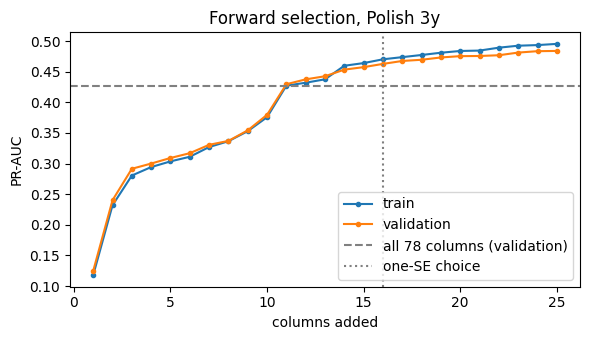

In [6]:
# Figure candidate: how fast the score builds as columns are added
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(fwd["n_columns"], fwd["train"], "o-", ms=3, label="train")
ax.plot(fwd["n_columns"], fwd["val"], "o-", ms=3, label="validation")
ax.axhline(full["val"], color="grey", linestyle="--", label="all 78 columns (validation)")
ax.axvline(K_FWD, color="grey", linestyle=":", label="one-SE choice")
ax.set_xlabel("columns added")
ax.set_ylabel("PR-AUC")
ax.set_title("Forward selection, Polish 3y")
ax.legend()
plt.tight_layout()
plt.show()

**Careful — this curve flatters itself.** Forward selection *chose* each column because it raised the validation
score. The same score is then used to judge it, so it is optimistic. The test set (Step 9) gives the honest number.

**What we found:**
- **16 columns** (one-SE choice) reach validation 0.463 — above all 78 columns (0.427). Most columns add nothing new.
- **Strongest single column:** `liq_quick_ratio` (cash-like assets ÷ short-term debt), 0.125 on its own — 2.6× better than guessing.
- **Blank flags come early** (steps 2, 4, 5): which values are missing is a strong signal, as in Week 2.
- **Biggest late jump at step 11** (+0.050, from 0.380 to 0.430): `act_st_liab_days_cogs` added next to its near-copy
  `act_curr_liab_days_cogs` (step 10). On its own a near-copy should add nothing — so the **gap between the two**
  carries the signal. This is why lasso kept both with opposite signs in Week 2.
- **Profitability arrives late** (steps 18–25) and adds about 0.003 per column.
- Train and validation stay within 0.01 at every step: no overfitting at these sizes.

## Step 5 — Backward elimination

**How it works:** the mirror image of forward selection.
1. Start with all 78 columns.
2. Try removing each one; drop the column whose removal **hurts validation PR-AUC least**.
3. Repeat, down to 5 columns.

**Speed trick:** at 78 columns every step means fitting ~390 models. To rank the removals, the solver stops a
little earlier (`tol=1e-3`), which makes it about 5× faster. The final chosen columns are refitted normally in Step 9.

Takes about 2 minutes.

In [7]:
def cv_subset_quick(cols, folds):
    # Same as cv_subset, but with a looser stopping rule — used only to rank which column to remove
    va = []
    for Ztr, ytr, Zva, yva in folds:
        m = LogisticRegression(C=1e6, max_iter=5000, tol=1e-3).fit(Ztr[:, cols], ytr)
        va.append(average_precision_score(yva, m.predict_proba(Zva[:, cols])[:, 1]))
    return {"val": np.mean(va), "val_sd": np.std(va)}

def backward_elimination(stop_at):
    keep = list(range(len(COLUMNS)))
    rows = [{"n_columns": len(keep), "removed": None, "family": None, **cv_subset_quick(keep, FOLDS)}]
    while len(keep) > stop_at:
        scores = Parallel(n_jobs=-1)(delayed(cv_subset_quick)([c for c in keep if c != j], FOLDS) for j in keep)
        best = int(np.argmax([s["val"] for s in scores]))
        j = keep.pop(best)
        rows.append({"n_columns": len(keep), "removed": COLUMNS[j], "family": family(COLUMNS[j]), **scores[best]})
    return pd.DataFrame(rows)

bwd = backward_elimination(5)
K_BWD = one_se_k(bwd, "n_columns")
removed = bwd.loc[bwd["n_columns"] >= K_BWD, "removed"].dropna().tolist()
BWD_COLS = [c for c in COLUMNS if c not in removed]
print(f"Best validation {bwd['val'].max():.3f} at {bwd.loc[bwd['val'].idxmax(), 'n_columns']} columns · "
      f"one-SE choice: {K_BWD} columns")
bwd.iloc[::5].round(3)   # every 5th step

Best validation 0.454 at 27 columns · one-SE choice: 14 columns


,n_columns,removed,family,val,val_sd
0,78,None,None,0.407,0.066
5,73,lev_st_liab_assets,lev,0.425,0.072
10,68,lev_assets_liab,lev,0.434,0.069
15,63,act_st_liab_days_sales,act,0.440,0.069
20,58,liq_wc_to_cash_sales,liq,0.444,0.075
25,53,prof_net_margin,prof,0.442,0.073
30,48,prof_net_profit_inventory,prof,0.443,0.071
35,43,blank_lev_debt_repay_days,blank,0.443,0.062
40,38,blank_act_inventory_turnover,blank,0.444,0.067
45,33,liq_cash_cycle_days,liq,0.448,0.064


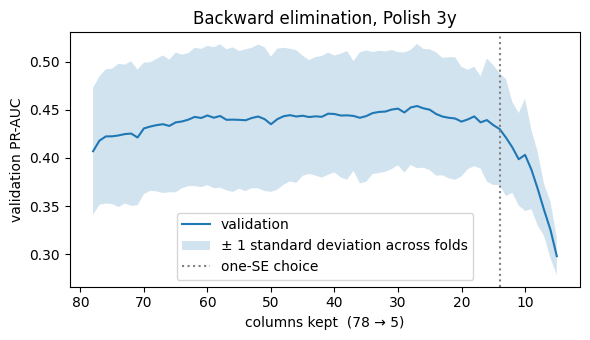

In [8]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(bwd["n_columns"], bwd["val"], "-", label="validation")
ax.fill_between(bwd["n_columns"], bwd["val"] - bwd["val_sd"], bwd["val"] + bwd["val_sd"], alpha=0.2,
                label="± 1 standard deviation across folds")
ax.axvline(K_BWD, color="grey", linestyle=":", label="one-SE choice")
ax.invert_xaxis()   # read left to right as columns are removed
ax.set_xlabel("columns kept  (78 → 5)")
ax.set_ylabel("validation PR-AUC")
ax.set_title("Backward elimination, Polish 3y")
ax.legend()
plt.tight_layout()
plt.show()

**What we found:**
- **Removing columns raised the score:** 0.407 with all 78 → peak 0.454 at 27 columns. The extra columns were adding noise.
- **A long flat stretch:** anywhere from about 60 down to 18 columns scores about 0.44 — the data is highly redundant.
- **One-SE choice: 14 columns** (bar = 0.454 − 0.060 ÷ √5 = 0.427). 27 is the best-scoring size, but 14 is within noise of it.
- **The cliff below about 13 columns** (8 columns: 0.368; 5 columns: about 0.30) shows where real signal starts being lost.
- The shaded band is ± 1 standard deviation; the one-SE rule uses the narrower standard error.

## Step 6 — Do the three selection methods agree?

Compare the columns chosen by forward selection, backward elimination and **Week 2's lasso** (C = 0.316,
refitted here on the same training set).

- **Overlap** = how many columns two methods share.
- If different methods keep picking the same columns, those columns are a reliable signal.

In [9]:
Z_train = prep().fit(X_train)   # one preparation fitted on all training firms, for the final models
lasso = LogisticRegression(C=0.316, l1_ratio=1.0, solver="saga", max_iter=5000, tol=1e-3, random_state=0)
lasso.fit(Z_train.transform(X_train), y_train)
LASSO_COLS = [c for c, b in zip(COLUMNS, lasso.coef_[0]) if abs(b) > 1e-8]

sets = {"forward": set(FWD_COLS), "backward": set(BWD_COLS), "lasso": set(LASSO_COLS)}
print({k: len(v) for k, v in sets.items()})
print("forward ∩ backward:", len(sets["forward"] & sets["backward"]),
      "· forward ∩ lasso:", len(sets["forward"] & sets["lasso"]),
      "· backward ∩ lasso:", len(sets["backward"] & sets["lasso"]),
      "· all three:", len(sets["forward"] & sets["backward"] & sets["lasso"]))

all_three = sorted(sets["forward"] & sets["backward"] & sets["lasso"])
pd.DataFrame({"column": all_three, "family": [family(c) for c in all_three]})

{'forward': 16, 'backward': 14, 'lasso': 50}
forward ∩ backward: 9 · forward ∩ lasso: 14 · backward ∩ lasso: 11 · all three: 9


,column,family
0,act_curr_liab_days_cogs,act
1,act_opex_st_liab,act
2,act_st_liab_days_cogs,act
3,blank_grow_sales_growth,blank
4,blank_lev_interest_coverage,blank
5,blank_prof_gross_profit_3y_assets,blank
6,lev_constant_cap_assets,lev
7,liq_quick_ratio,liq
8,size_log_assets,size


In [10]:
# Share of each family's columns that each method keeps (families differ in size)
family_size = pd.Series([family(c) for c in COLUMNS]).value_counts()
share = pd.DataFrame({name: pd.Series([family(c) for c in cols]).value_counts() for name, cols in sets.items()})
share = share.reindex(family_size.index).fillna(0).div(family_size, axis=0).round(2)
share.insert(0, "family_size", family_size)
share

,family_size,forward,backward,lasso
prof,19,0.05,0.00,0.63
blank,19,0.32,0.21,0.63
lev,16,0.06,0.12,0.56
act,14,0.36,0.36,0.71
liq,9,0.22,0.22,0.67
size,1,1.00,1.00,1.00


**What we found:**
- **Strong agreement:** 14 of forward's 16 columns are also in lasso; 11 of backward's 14 are too.
- **9 columns are picked by all three methods** — the reliable core:
  - activity: `act_curr_liab_days_cogs`, `act_st_liab_days_cogs`, `act_opex_st_liab` (how long short-term debts take to pay);
  - liquidity: `liq_quick_ratio`; leverage: `lev_constant_cap_assets`; size: `size_log_assets`;
  - 3 blank flags: sales growth, interest coverage, 3-year gross profit.
- **No profitability column is in the core.** Forward keeps 1 of 19 profitability ratios (5%), backward keeps 0.
- **Activity is kept most** by both forward and backward (36%).
- Read the family table **down each column**: lasso's shares are higher everywhere only because it keeps 50 columns.

## Step 7 — PCR: merge the columns, then predict

**How it works:**
1. **PCA** builds new columns ("components"). Component 1 is the single direction that captures the most
   variation across all ratios; component 2 the most of what is left; and so on. Near-copies collapse together
   into the same component.
2. Logistic regression is then fitted on the first *k* components instead of the 78 columns.

**The catch:** PCA never looks at bankruptcy. It keeps the directions where firms **vary most** — which are not
necessarily the directions that **predict failure**.

**Note:** with all 78 components, PCR is the full model just rotated, so it should score like "no penalty".
Small differences come from the solver stopping at slightly different points when columns are near-copies.

In [11]:
pca_all = PCA().fit(FOLDS[0][0])
cum = np.cumsum(pca_all.explained_variance_ratio_)
print("Share of total variation captured by the first k components:")
print({k: round(cum[k - 1], 3) for k in [1, 2, 3, 5, 10, 20, 30]})

K_GRID = [1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 50, 60, 70, 78]

def cv_pcr(k):
    tr, va = [], []
    for Ztr, ytr, Zva, yva in FOLDS:
        pca = PCA(n_components=k).fit(Ztr)
        m = logit().fit(pca.transform(Ztr), ytr)
        tr.append(average_precision_score(ytr, m.predict_proba(pca.transform(Ztr))[:, 1]))
        va.append(average_precision_score(yva, m.predict_proba(pca.transform(Zva))[:, 1]))
    return {"k": k, "train": np.mean(tr), "val": np.mean(va), "val_sd": np.std(va)}

pcr = pd.DataFrame([cv_pcr(k) for k in K_GRID])
K_PCR = one_se_k(pcr, "k")
print(f"One-SE choice: {K_PCR} components")
pcr.round(3)

Share of total variation captured by the first k components:
{1: np.float64(0.26), 2: np.float64(0.423), 3: np.float64(0.524), 5: np.float64(0.658), 10: np.float64(0.825), 20: np.float64(0.936), 30: np.float64(0.972)}
One-SE choice: 78 components


,k,train,val,val_sd
0,1,0.062,0.065,0.006
1,2,0.116,0.124,0.011
2,3,0.118,0.123,0.010
3,5,0.180,0.190,0.021
4,8,0.249,0.256,0.037
5,10,0.296,0.301,0.042
6,15,0.313,0.308,0.038
7,20,0.321,0.315,0.038
8,30,0.336,0.319,0.038
9,40,0.348,0.322,0.038


**Which families make up the top components?** Each component is a weighted mix of the 78 columns. The squared
weights add up to 1, so summing them by family gives each family's share of that component.

In [12]:
def family_shares(weights):
    # weights: one row per component, one column per original column
    w2 = pd.DataFrame(weights ** 2, columns=COLUMNS).T
    w2 = w2.div(w2.sum(axis=0), axis=1)
    return w2.groupby([family(c) for c in COLUMNS]).sum().round(2)

pc_shares = family_shares(pca_all.components_[:3])
pc_shares.columns = ["PC1", "PC2", "PC3"]
pc_shares["family_size_share"] = (family_size / len(COLUMNS)).round(2)   # what an even mix would look like
pc_shares

,PC1,PC2,PC3,family_size_share
act,0.05,0.06,0.04,0.18
blank,0.71,0.23,0.93,0.24
lev,0.11,0.18,0.00,0.21
liq,0.07,0.08,0.00,0.12
prof,0.06,0.45,0.01,0.24
size,0.00,0.00,0.00,0.01


**What we found:**
- **PCR gives no compression:** 10 components hold 82.5% of the variation but score only 0.301; it needs all 78
  components (0.437) to match the full model. One-SE choice: 78.
- **Why:** PCA keeps what *varies most* across firms — PC1 is 71% blank flags, PC2 is 45% profitability, and activity
  is only about 5% of each. Those are weak bankruptcy signals.
- The real signal (e.g. the small gap between the two activity near-copies) is a **low-variation** direction, so PCA
  ranks it last.
- **Varies most ≠ predicts most** — the classic weakness of PCR, shown on real data.

## Step 8 — PLS: merge the columns *with bankruptcy in mind*

**How it works:** like PCR, PLS builds a few components from the 78 columns. The difference: each component
is chosen to be **related to bankruptcy**, not just to capture variation.

**In code:** `PLSRegression` treats bankrupt = 1 / survived = 0 as a number and outputs a risk score.
PR-AUC only needs the **ranking** of firms, so a score works as well as a probability.

In [13]:
def cv_pls(k):
    tr, va = [], []
    for Ztr, ytr, Zva, yva in FOLDS:
        m = PLSRegression(n_components=k, scale=False).fit(Ztr, ytr)
        tr.append(average_precision_score(ytr, m.predict(Ztr).ravel()))
        va.append(average_precision_score(yva, m.predict(Zva).ravel()))
    return {"k": k, "train": np.mean(tr), "val": np.mean(va), "val_sd": np.std(va)}

# Stops at 70: with every component, PLS has nothing left to compress and becomes numerically unstable
pls = pd.DataFrame([cv_pls(k) for k in K_GRID if k <= 70])
K_PLS = one_se_k(pls, "k")
print(f"One-SE choice: {K_PLS} components")
pls.round(3)

One-SE choice: 20 components


,k,train,val,val_sd
0,1,0.225,0.230,0.026
1,2,0.234,0.238,0.031
2,3,0.259,0.263,0.042
3,5,0.301,0.294,0.042
4,8,0.340,0.314,0.041
5,10,0.341,0.313,0.042
6,15,0.398,0.358,0.051
7,20,0.419,0.382,0.055
8,30,0.429,0.391,0.056
9,40,0.439,0.405,0.058


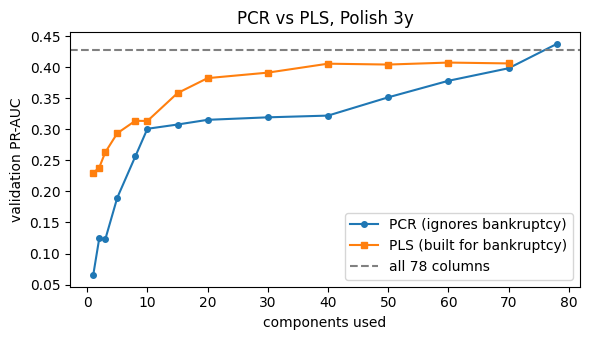

In [14]:
# Figure candidate: PCR vs PLS — how many components each needs
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(pcr["k"], pcr["val"], "o-", ms=4, label="PCR (ignores bankruptcy)")
ax.plot(pls["k"], pls["val"], "s-", ms=4, label="PLS (built for bankruptcy)")
ax.axhline(full["val"], color="grey", linestyle="--", label="all 78 columns")
ax.set_xlabel("components used")
ax.set_ylabel("validation PR-AUC")
ax.set_title("PCR vs PLS, Polish 3y")
ax.legend()
plt.tight_layout()
plt.show()

In [15]:
pls_full = PLSRegression(n_components=3, scale=False).fit(FOLDS[0][0], FOLDS[0][1])
pls_shares = family_shares(pls_full.x_weights_.T)
pls_shares.columns = ["PLS1", "PLS2", "PLS3"]
pls_shares["family_size_share"] = (family_size / len(COLUMNS)).round(2)
pls_shares

,PLS1,PLS2,PLS3,family_size_share
act,0.04,0.09,0.02,0.18
blank,0.52,0.48,0.84,0.24
lev,0.15,0.13,0.04,0.21
liq,0.08,0.06,0.03,0.12
prof,0.21,0.24,0.04,0.24
size,0.00,0.00,0.03,0.01


**What we found:**
- **PLS beats PCR with few components:** 1 component scores 0.230 vs PCR's 0.065, because PLS builds components
  with bankruptcy in mind.
- **But it still needs about 20 components** (one-SE choice, validation 0.382) and never reaches the 16-column forward model.
- **PLS1 weights:** blank flags 52% (vs an even share of 24%), profitability 21%, activity only 4%.
- **Why it falls short:** PLS builds broad blends of many columns; the bankruptcy signal here is **narrow** — a few
  specific columns and the gap between near-copies. Blending dilutes it.

## Step 9 — Final comparison on the test set

Every method refitted on all training firms with its chosen size, then scored **once** on the same test firms as
Week 2. The 95% range comes from re-drawing the test set 1,000 times (only 99 bankrupt firms, so scores are noisy).

In [16]:
Ztr, Zte = Z_train.transform(X_train), Z_train.transform(X_test)
idx = {c: i for i, c in enumerate(COLUMNS)}

def scores_logit(cols):
    ci = [idx[c] for c in cols]
    m = logit().fit(Ztr[:, ci], y_train)
    return m.predict_proba(Ztr[:, ci])[:, 1], m.predict_proba(Zte[:, ci])[:, 1]

pca_k = PCA(n_components=K_PCR).fit(Ztr)
m_pcr = logit().fit(pca_k.transform(Ztr), y_train)
m_pls = PLSRegression(n_components=K_PLS, scale=False).fit(Ztr, y_train)

final = {
    "no penalty (all 78)":            (78, scores_logit(COLUMNS)),
    "lasso, Week 2":                  (len(LASSO_COLS), (lasso.predict_proba(Ztr)[:, 1], lasso.predict_proba(Zte)[:, 1])),
    f"forward ({K_FWD} columns)":     (K_FWD, scores_logit(FWD_COLS)),
    f"backward ({K_BWD} columns)":    (K_BWD, scores_logit(BWD_COLS)),
    f"PCR ({K_PCR} components)":      (K_PCR, (m_pcr.predict_proba(pca_k.transform(Ztr))[:, 1],
                                               m_pcr.predict_proba(pca_k.transform(Zte))[:, 1])),
    f"PLS ({K_PLS} components)":      (K_PLS, (m_pls.predict(Ztr).ravel(), m_pls.predict(Zte).ravel())),
}

rng = np.random.default_rng(0)
yt = y_test.to_numpy()
boot = [rng.integers(0, len(yt), len(yt)) for _ in range(1000)]

rows = []
for name, (size, (p_tr, p_te)) in final.items():
    tr, te = average_precision_score(y_train, p_tr), average_precision_score(yt, p_te)
    lo, hi = np.percentile([average_precision_score(yt[i], p_te[i]) for i in boot], [2.5, 97.5])
    rows.append({"model": name, "size": size, "train_PR_AUC": tr, "test_PR_AUC": te,
                 "test_95%_range": f"{lo:.3f}–{hi:.3f}", "gap": tr - te, "test_lift": te / yt.mean()})
comparison = pd.DataFrame(rows)
comparison.round(3)

,model,size,train_PR_AUC,test_PR_AUC,test_95%_range,gap,test_lift
0,no penalty (all 78),78,0.513,0.457,0.365–0.571,0.055,9.625
1,"lasso, Week 2",50,0.450,0.479,0.382–0.588,-0.029,10.076
2,forward (16 columns),16,0.468,0.540,0.429–0.654,-0.072,11.361
3,backward (14 columns),14,0.434,0.474,0.372–0.588,-0.040,9.986
4,PCR (78 components),78,0.518,0.493,0.394–0.613,0.025,10.377
5,PLS (20 components),20,0.417,0.410,0.315–0.514,0.007,8.627


**What we found:**
- **Selection wins on simplicity:** forward (16 columns, 0.540) and backward (14 columns, 0.474) match or beat all
  78 columns (0.457) and lasso (50 columns, 0.479). About 80% of the columns can go.
- **Forward held up on the test set** — its flattering validation curve did not collapse. But the 95% ranges overlap,
  so the honest reading is "at least as good, with 16 columns", not "best".
- **Merging does not help here:** PCR needs all 78 components (0.493 — the full model rotated); PLS with 20
  components is the lowest (0.410).
- **Overfitting:** only the full model has a clearly positive gap (0.055). Cutting columns removes it — the same
  control as Week 2's penalty, achieved by choosing fewer columns.

## Step 10 — RQ2: do the methods agree on families?

Pull together each method's view of the families: share of each family's columns kept (forward, backward, lasso)
and each family's share of the first PLS component.

In [17]:
rq2 = share.drop(columns="family_size").copy()
rq2["PLS1_weight"] = pls_shares["PLS1"]
rq2["even_mix"] = (family_size / len(COLUMNS)).round(2)
rq2

,forward,backward,lasso,PLS1_weight,even_mix
prof,0.05,0.00,0.63,0.21,0.24
blank,0.32,0.21,0.63,0.52,0.24
lev,0.06,0.12,0.56,0.15,0.21
act,0.36,0.36,0.71,0.04,0.18
liq,0.22,0.22,0.67,0.08,0.12
size,1.00,1.00,1.00,0.00,0.01


**How to read:** for forward/backward/lasso, read **down each column** — which family has the highest share kept?
Don't compare across methods: lasso keeps 50 columns, so its shares are higher everywhere. For `PLS1_weight`,
compare with `even_mix`: a family above its even share is over-represented in the first PLS component.

**What we found:**
- **The selection methods agree:** activity is kept most (36% forward and backward) and profitability least
  (5% and 0%). Lasso (Week 2) gave the same ranking at the ends.
- **PLS disagrees:** it over-weights blank flags (52%) and gives activity almost nothing (4%). Steps 7–8 explain
  why — merging methods follow overall patterns, not the specific columns that predict bankruptcy.
- **RQ2, method 2 of 3:** activity ratios (payment periods and turnover) carry the signal; profitability is mostly
  redundant once the other columns are known. Two methods now agree; Week 6 (random forest) is the third check.

## Expected vs unexpected

These expectations were written **before** Week 3 ran: in the capstone proposal, in the Week 2 findings log, and in
course theory.

**Expected**
- PCR will compress the near-copies into a few components whose loadings show which families group together
  (proposal) → PCR needed all 78 components; its top components are blank flags and profitability, which predict
  little → **wrong**: varies most ≠ predicts most.
- PCR will resolve the activity near-copy group that lasso could not (Week 2 findings log) → it did not; forward
  selection showed the *gap* between the near-copies is the signal → **wrong, and it explained the puzzle instead**.
- PLS will need fewer components than PCR, because it uses the target (course theory) → 1 PLS component scored
  0.230 vs 0.065 for PCR → **confirmed** — but PLS still needed about 20 components.
- Families will agree across at least two of three methods (proposal success criterion) → forward, backward and
  lasso all rank activity highest and profitability lowest → **confirmed**.

**Unexpected**
- Fewer columns scored **higher**: 14–16 columns matched or beat all 78 on both validation and test.
- Profitability — usually seen as central to bankruptcy — was almost entirely dropped (forward 1 of 19, backward 0).
- Two "near-copies" carry signal *together*: adding the second one gave the biggest late jump (+0.050).

## Conclusions

1. **Forward selection:** 16 columns reach validation 0.463 and test 0.540 — at least as good as all 78. The quick ratio
   is the strongest single column; profitability arrives last.
2. **Backward elimination:** 14 columns (one-SE) score within noise of the best (27 columns, 0.454). Removing columns
   raised the score, so the full model carries noise.
3. **Agreement with lasso:** 9 columns are chosen by all three methods — activity, quick ratio, long-term funding,
   size and three blank flags. None is a profitability ratio.
4. **PCR:** no compression — it needs all 78 components. The largest sources of variation (blank patterns,
   profitability) are not where the bankruptcy signal is.
5. **PLS:** beats PCR with few components (0.230 vs 0.065 with one), but needs about 20 and is the weakest on test (0.410).
6. **Test set:** all methods score 0.41–0.54 (8.6–11.4× better than random), with overlapping ranges. **Choosing 14–16
   columns keeps the accuracy of 78; merging columns does not help.**
7. **RQ2 (method 2 of 3):** activity ratios carry the signal; profitability is mostly redundant. Selection agrees with
   lasso; Week 6 is the third check.
8. **Meaning of the hyperparameters:** the number of columns (forward/backward) and of components (PCR/PLS) control how
   simple the model is. The one-SE rule picks the fewest that are within noise of the best: 16 and 14 columns, 78 and
   20 components. Below about 13 columns real signal is lost.